# Rated power: every sensor stretched from part load to 60 kW

Part load never went above ~34 kW DC. This notebook reads every logged sensor at **0 … 60 kW** by fitting a straight
line in power on the part-load minutes, then solves the string voltages and currents so that ΣV·I really adds up to the
power, and works out the gas by Faraday.

It calls the functions in `scripts/rated_power_extrapolation.py` (the same code the command line runs) and writes the
same files to `03_data_analysis/rated_power/`.

| § | Step | Function |
|---|---|---|
| 1 | Part-load minutes, P_dc = Σ V·I over 5 strings | `pl_minutes` |
| 2 | Straight line `sensor = a + b·P` per sensor, glitch minutes dropped | `extrapolate` |
| 3 | Trust: R² and leave-one-run-out error at the top of each run | `extrapolate` |
| 4 | Electrical: V = a + b·I per string, equal string current, gas by Faraday | `electrical` |
| 5 | Notes and limits (trips, cell protection, actuators past 100 %) | — |
| 6 | Save outputs | — |

**Limit:** a straight line in power only. Part-load minutes are not steady (temperatures still rising when a run ends),
so heat-driven sensors read low; the stack and BOP temperatures need the twin heat balance (`05_twin_2d`).

In [1]:
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "scripts")   # helper modules live in 03_data_analysis/scripts/
import rated_power_extrapolation as rp

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, GRAY, ORANGE, RED = "#2f5f9e", "#9aa4b3", "#b86e00", "#b03a2e"

rp.self_check()
print("steps (kW):", rp.STEPS, "| rated", rp.RATED_KW, "kW |", rp.CELLS, "cells per string")

steps (kW): [0, 10, 20, 30, 34, 40, 50, 60] | rated 60.0 kW | 476 cells per string


## 1. Part-load minutes

Minutes labelled **Part load** in `plant_stages_1min.parquet`, raw 10-s data averaged to 1 min, logger dropouts (−1)
removed. DC power = Σ string voltage × string current. A *run* is an unbroken stretch of part-load minutes.

In [2]:
d = rp.pl_minutes()
runs = d.groupby("run").agg(minutes=("P_dc_kW", "size"), P_mean_kW=("P_dc_kW", "mean"), P_max_kW=("P_dc_kW", "max"))
runs.insert(0, "start", d.index.to_series().groupby(d.run.values).first())
print(f"{len(d)} part-load minutes, {d.run.nunique()} runs, P max {d.P_dc_kW.max():.1f} kW")
runs.round(1)

268 part-load minutes, 10 runs, P max 33.6 kW


,start,minutes,P_mean_kW,P_max_kW
run,,,,
1,2026-03-13 10:03:00,8,7.7,10.9
2,2026-03-13 13:26:00,17,13.9,19.1
3,2026-03-19 10:20:00,17,11.7,15.0
4,2026-03-19 15:31:00,18,16.0,21.2
5,2026-03-24 08:54:00,32,20.1,31.1
6,2026-03-24 13:54:00,43,10.7,18.7
7,2026-03-25 08:18:00,33,12.3,23.7
8,2026-03-25 10:17:00,33,17.1,25.0
9,2026-03-25 14:30:00,44,23.3,33.6


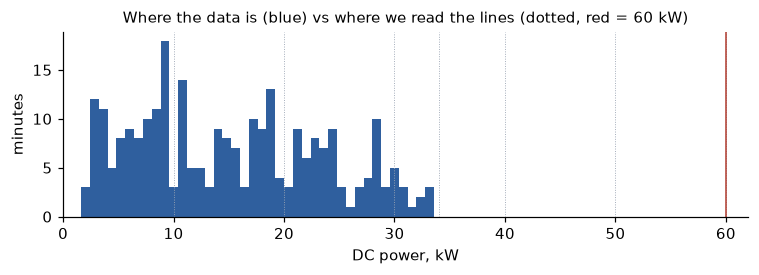

In [3]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.hist(d.P_dc_kW, bins=40, color=BLUE)
for p in rp.STEPS:
    ax.axvline(p, color=GRAY, lw=0.6, ls=":")
ax.axvline(rp.RATED_KW, color=RED, lw=1)
ax.set_xlim(0, 62)
ax.set_xlabel("DC power, kW"); ax.set_ylabel("minutes")
ax.set_title("Where the data is (blue) vs where we read the lines (dotted, red = 60 kW)", fontsize=10)
plt.tight_layout()

## 2. A straight line per sensor

For each numeric sensor with ≥ 60 minutes and some spread: fit `sensor = a + b·P`, drop minutes more than 4 robust
sigma off that line (glitches such as 93 V strings or 28 V cells), fit again and read the line at each step.

Each sensor is put in one group:
* **follows power**: R² ≥ 0.5 and the held-out error ≤ 25 % of the seen range; the line is used.
* **temperature / cell (lags power)**: physical but weak line; the line is still used, low trust.
* **operator-set / no link**: set points, modes; kept at their part-load mean.

In [4]:
t = rp.extrapolate(d)
print(len(t), "changing sensors")
t.group.value_counts().to_frame("sensors")

464 changing sensors


,sensors
group,
operator-set / no link,251
temperature / cell (lags power),145
follows power,68


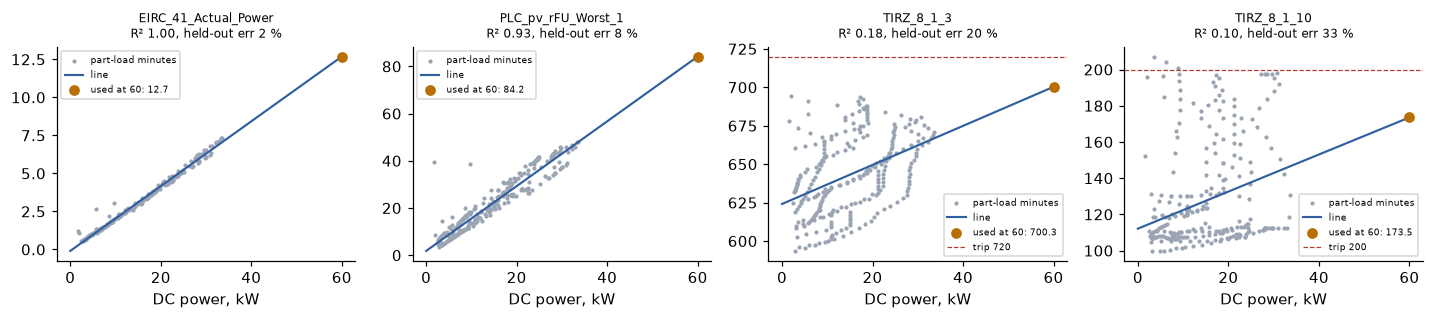

In [5]:
EXAMPLES = ["EIRC_41_Actual_Power", "PLC_pv_rFU_Worst_1", "TIRZ_8_1_3", "TIRZ_8_1_10"]
xs = np.linspace(0, rp.RATED_KW, 2)
T = t.set_index("sensor")
fig, axs = plt.subplots(1, len(EXAMPLES), figsize=(13, 3))
for ax, s in zip(axs, EXAMPLES):
    r = T.loc[s]
    ax.scatter(d.P_dc_kW, d[s], s=3, color=GRAY, label="part-load minutes")
    ax.plot(xs, r.at_0kW + r.slope_per_kW * xs, color=BLUE, lw=1.4, label="line")
    ax.scatter([rp.RATED_KW], [r.use_60kW], color=ORANGE, zorder=3, label=f"used at 60: {r.use_60kW:.1f}")
    if s in rp.LIMITS:
        ax.axhline(rp.LIMITS[s], color=RED, lw=0.8, ls="--", label=f"trip {rp.LIMITS[s]:.0f}")
    ax.set_title(f"{s}\nR² {r.r2:.2f}, held-out err {r.loro_err_pct_of_range:.0f} %", fontsize=8)
    ax.set_xlabel("DC power, kW"); ax.legend(fontsize=6)
plt.tight_layout()

## 3. How far can each line be trusted?

Leave one part-load run out, fit on the rest, predict the held-out run's **top-power quarter** (minutes above its
75th power percentile). The mean error, as % of the sensor's seen range, says how well the line carries past the
data it was fitted on.

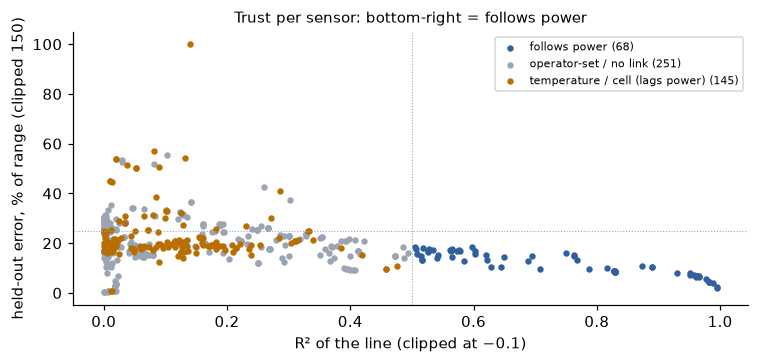

In [6]:
colors = {"follows power": BLUE, "temperature / cell (lags power)": ORANGE, "operator-set / no link": GRAY}
fig, ax = plt.subplots(figsize=(7, 3.4))
for g, sub in t.groupby("group"):
    ax.scatter(sub.r2.clip(-0.1, 1), sub.loro_err_pct_of_range.clip(0, 150), s=10, color=colors[g], label=f"{g} ({len(sub)})")
ax.axvline(0.5, color=GRAY, lw=0.7, ls=":"); ax.axhline(25, color=GRAY, lw=0.7, ls=":")
ax.set_xlabel("R² of the line (clipped at −0.1)"); ax.set_ylabel("held-out error, % of range (clipped 150)")
ax.legend(fontsize=7); ax.set_title("Trust per sensor: bottom-right = follows power", fontsize=10)
plt.tight_layout()

In [7]:
cols = ["sensor", "group", "r2", "loro_err_pct_of_range", "seen_min", "seen_max", "at_34kW", "at_60kW"]
t[t.power_driven][cols].head(25).round(3)

,sensor,group,r2,loro_err_pct_of_range,seen_min,seen_max,at_34kW,at_60kW
415,EIRC_41_Actual_Power,follows power,0.995,2.137,0.527,7.332,7.145,12.683
431,EIRC_43_Actual_Power,follows power,0.995,2.573,0.498,7.122,7.043,12.459
423,EIRC_42_Actual_Power,follows power,0.989,3.879,0.469,7.445,7.337,13.013
410,EIRC_41_CurrentMon,follows power,0.982,4.574,1.127,17.995,16.880,30.329
416,EIRC_41_OUT_Analog,follows power,0.982,4.572,1.194,19.542,18.349,33.009
272,PLC_hostSetp_ctrl_ctEIRC41_rCurrMonitor,follows power,0.982,4.204,1.115,17.995,16.826,30.243
447,EIRC_45_Actual_Power,follows power,0.976,5.550,0.499,7.684,7.384,13.074
432,EIRC_43_OUT_Analog,follows power,0.966,6.992,1.194,19.542,18.724,33.566
278,PLC_hostSetp_ctrl_ctEIRC42_rCurrMonitor,follows power,0.966,6.239,0.924,17.981,17.114,30.731
426,EIRC_43_CurrentMon,follows power,0.964,6.983,1.093,18.000,17.197,30.770


## 4. Electrical: voltage, current and gas at each step

Separate straight lines for string V and I in power give only ~50 kW at 60 (V·I is not linear in P). Instead:

* per string `V = a + b·I` (robust line on part-load minutes);
* every string carries the **same current** u (the part-load split, string 4.4 at ~73 %, was an operator setting and
  would put four strings above the 42 A El.Load rating);
* solve `Σ (a_k + b_k·u)·u = 1000·P` for u at each step: same rated point as the twin (≈ 40.2 A at 60 kW);
* gas: Faraday for CH₄ (8 e⁻ per molecule) at the fuel-use trend from `rFU_Worst_1..5`.

In [8]:
e = rp.electrical(d, t)          # also writes the solved V, I and gas into t's use_* columns
assert np.allclose(e.P_check_kW, e.P_kW, atol=0.01)
display(e.attrs["VI"].round(3))
e.round(2)

,string,V_at_0A,V_per_A,current_share
0,1,486.664,-4.662,1.0
1,2,492.271,-4.866,1.0
2,3,482.523,-5.476,1.0
3,4,477.357,-3.809,1.0
4,5,501.163,-4.746,1.0


,P_kW,I_1_A,I_2_A,I_3_A,I_4_A,I_5_A,V_1_V,V_2_V,V_3_V,V_4_V,V_5_V,V_cell_avg,P_check_kW,FU_pct,NG_lnmin
0,0,-0.00,-0.00,-0.00,-0.00,-0.00,486.66,492.27,482.52,477.36,501.16,1.03,0.0,2.60,0.00
1,10,4.27,4.27,4.27,4.27,4.27,466.73,471.47,459.11,461.08,480.87,0.98,10.0,15.33,115.67
2,20,8.97,8.97,8.97,8.97,8.97,444.82,448.60,433.38,443.18,458.57,0.94,20.0,28.05,132.66
3,30,14.26,14.26,14.26,14.26,14.26,420.19,422.89,404.44,423.05,433.49,0.88,30.0,40.78,144.98
4,34,16.59,16.59,16.59,16.59,16.59,409.30,411.53,391.65,414.16,422.41,0.86,34.0,45.87,150.00
5,40,20.42,20.42,20.42,20.42,20.42,391.46,392.91,370.70,399.59,404.25,0.82,40.0,53.51,158.25
6,50,28.14,28.14,28.14,28.14,28.14,355.48,355.36,328.44,370.20,367.63,0.75,50.0,66.23,176.15
7,60,40.18,40.18,40.18,40.18,40.18,299.35,296.78,262.51,324.34,310.49,0.63,60.0,78.96,210.98


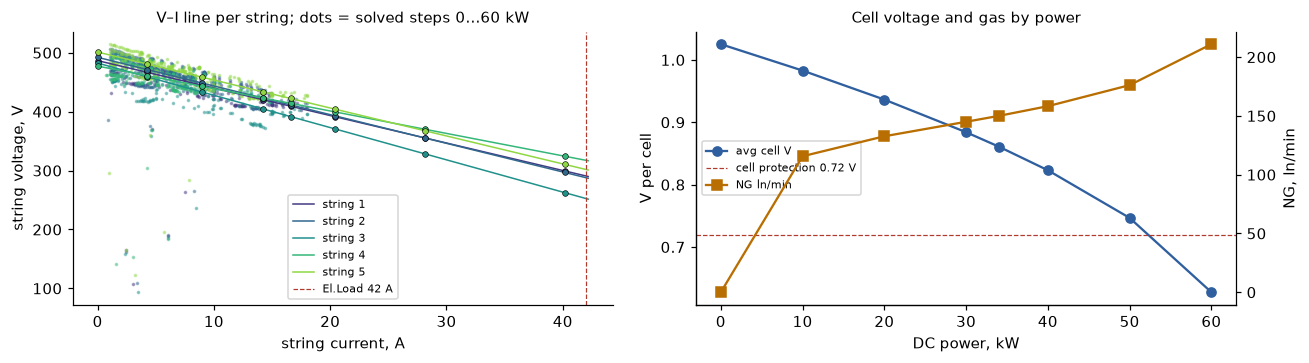

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4))
vi = e.attrs["VI"]
I_line = np.linspace(0, e[[f"I_{k}_A" for k in range(1, 6)]].values.max() * 1.05, 2)
for k, (v, i) in enumerate(zip(rp.VOLT, rp.CURR), start=1):
    c = plt.cm.viridis(k / 6)
    axs[0].scatter(d[i], d[v], s=2, color=c, alpha=0.4)
    r = vi.iloc[k - 1]
    axs[0].plot(I_line, r.V_at_0A + r.V_per_A * I_line, color=c, lw=1, label=f"string {k}")
    axs[0].scatter(e[f"I_{k}_A"], e[f"V_{k}_V"], s=14, color=c, edgecolor="k", lw=0.4, zorder=3)
axs[0].axvline(42, color=RED, lw=0.8, ls="--", label="El.Load 42 A")
axs[0].set_xlabel("string current, A"); axs[0].set_ylabel("string voltage, V"); axs[0].legend(fontsize=7)
axs[0].set_title("V–I line per string; dots = solved steps 0…60 kW", fontsize=10)

ax2 = axs[1]
ax2.plot(e.P_kW, e.V_cell_avg, "o-", color=BLUE, label="avg cell V")
ax2.axhline(0.72, color=RED, lw=0.8, ls="--", label="cell protection 0.72 V")
ax2.set_xlabel("DC power, kW"); ax2.set_ylabel("V per cell")
ax3 = ax2.twinx()
ax3.plot(e.P_kW, e.NG_lnmin, "s-", color=ORANGE, label="NG ln/min")
ax3.set_ylabel("NG, ln/min")
ax3.spines["right"].set_visible(True)
h, h3 = ax2.get_legend_handles_labels(), ax3.get_legend_handles_labels()
ax2.legend(h[0] + h3[0], h[1] + h3[1], fontsize=7, loc="center left")
ax2.set_title("Cell voltage and gas by power", fontsize=10)
plt.tight_layout()

## 5. Notes and limits

Sensors where the straight line runs into something the plant would not allow: a trip (stack TIRZ 8.1.3 at 720 °C,
exhaust TIRZ 8.1.10 at 200 °C), the 0.72 V cell protection, or an actuator past 0 / 100 %.

In [10]:
t[t.note != ""][["sensor", "group", "at_34kW", "use_60kW", "note"]].round(2)

,sensor,group,at_34kW,use_60kW,note
272,PLC_hostSetp_ctrl_ctEIRC41_rCurrMonitor,follows power,16.83,40.18,V-I solved so sum V*I = P (electrical_60kW.csv)
278,PLC_hostSetp_ctrl_ctEIRC42_rCurrMonitor,follows power,17.11,40.18,V-I solved so sum V*I = P (electrical_60kW.csv)
284,PLC_hostSetp_ctrl_ctEIRC43_rCurrMonitor,follows power,17.11,40.18,V-I solved so sum V*I = P (electrical_60kW.csv)
296,PLC_hostSetp_ctrl_ctEIRC45_rCurrMonitor,follows power,16.76,40.18,V-I solved so sum V*I = P (electrical_60kW.csv)
290,PLC_hostSetp_ctrl_ctEIRC44_rCurrMonitor,follows power,11.61,40.18,V-I solved so sum V*I = P (electrical_60kW.csv)
295,PLC_hostSetp_ctrl_ctEIRC45_rVoltMonitor,follows power,424.90,310.49,V-I solved so sum V*I = P (electrical_60kW.csv)
289,PLC_hostSetp_ctrl_ctEIRC44_rVoltMonitor,follows power,426.73,324.34,V-I solved so sum V*I = P (electrical_60kW.csv)
271,PLC_hostSetp_ctrl_ctEIRC41_rVoltMonitor,follows power,410.42,299.35,V-I solved so sum V*I = P (electrical_60kW.csv)
277,PLC_hostSetp_ctrl_ctEIRC42_rVoltMonitor,follows power,412.94,296.78,V-I solved so sum V*I = P (electrical_60kW.csv)
256,ct_FIRC_14_PV_ProcessValue,operator-set / no link,160.43,210.98,gas by Faraday from solved currents at the fuel-use trend (operator steps hide the link)


## 6. Save outputs

Same files as `python scripts/rated_power_extrapolation.py`.

In [11]:
rp.OUT.mkdir(exist_ok=True)
d.to_parquet(rp.OUT / "pl_minutes.parquet")
e.to_csv(rp.OUT / "electrical_60kW.csv", index=False)
e.attrs["VI"].to_csv(rp.OUT / "string_vi_fit.csv", index=False)
t.to_csv(rp.OUT / "sensor_extrapolation.csv", index=False)
t.round(4).to_excel(rp.OUT / "sensor_extrapolation.xlsx", index=False)
print("written to", rp.OUT)

written to C:\Users\mrgur\Guru_prasaath\06_Projects\01_POC\03_data_analysis\rated_power
